Task 1: Load the dataset into a Pandas DataFrame from the source 
repository or course mirror, assigning appropriate column names.

In [59]:
import pandas as pd

# Import Dataset from GitHub Repo
git_url = 'https://raw.githubusercontent.com/tstef87/StefanoCSC672/refs/heads/master/HW5/pima-indians-diabetes.csv'

cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
        "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]

df = pd.read_csv(git_url, header=None, names=cols)
df.shape

(768, 9)

Task 2: Use structural inspection methods (head(), info(), describe()) to 
analyze feature distributions and identify non-standard placeholder values.

In [60]:
# Display Data Frame Head
print("\n --- DF Head ---")
print(df.head())

# Display Data Frame Info
print("\n --- DF INFO ---")
df.info()

print("\n--- Feature Summary ---")
display(df[cols].describe())


 --- DF Head ---
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

 --- DF INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64 

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [61]:
# Find 0 values
print("--- 0 Values ---")
missing_value_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print((df[missing_value_cols] == 0).sum())

--- 0 Values ---
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


Task 3: Quantify and handle implicit missing values using SimpleImputer.

In [62]:
from sklearn.impute import SimpleImputer
import numpy as np

#  Imputer for Numeric and Catagorical 
num_imputer = SimpleImputer(strategy="median")

df[missing_value_cols] = df[missing_value_cols].replace(0, np.nan)
df[missing_value_cols] = num_imputer.fit_transform(df[missing_value_cols])

# find Null values 
print("--- Null Values ---")
df.isnull().sum()

--- Null Values ---


,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


Task 4: Build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling.

In [63]:
# Imports 
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.model_selection import train_test_split


x_cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
        "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]

X = df[x_cols]
y = df["Outcome"]

# Numeric Pipeline 
num_pipeline = make_pipeline(
    SimpleImputer(strategy="median"), 
    StandardScaler())

# Perform Column Transformer 
preprocessing = ColumnTransformer([
    ("num", num_pipeline, x_cols),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

Task 5: Train both a Hard Voting Classifier and a Soft Voting Classifier combining base models (e.g., Logistic Regression, Support Vector Classifier, and a Decision Tree), then evaluate their test accuracy and classification reports. Use must use appropriate plots to show the results.

In [64]:
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

base_models = [
    ("lr", LogisticRegression(max_iter=1000, random_state=42)),
    ("svc", SVC(probability=True, random_state=42)),
    ("dt", DecisionTreeClassifier(max_depth=5, random_state=42)),
]

# Hard Voting
hard_clf = Pipeline([("prep", preprocessing),
                     ("vote", VotingClassifier(base_models, voting="hard"))])
# Soft Voting
soft_clf = Pipeline([("prep", preprocessing),
                     ("vote", VotingClassifier(base_models, voting="soft"))])


hard_clf.fit(X_train, y_train)
soft_clf.fit(X_train, y_train)


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['Pregnancies', 'Glucose',
                                                   'BloodPressure',
                                                   'SkinThickness', 'Insulin',
                                                   'BMI',
                                                   'DiabetesPedigreeFunction',
                                                   'Age'])])),
                ('vote',
                 VotingClassifier(estimators=[('lr',
                                               LogisticRegression(max_iter=1000,
                                                                  random_state=42)),
                                              ('svc',
                                               SVC(probability=True,
                                                   random_state=42)),
                                              ('dt',
                                               DecisionTreeClassifier(max_depth=5,
                                                                      random_state=42))],
                                  voting='soft'))])

In [65]:
X_test_prep = hard_clf.named_steps["prep"].transform(X_test)
results = {}
for name, clf in hard_clf.named_steps["vote"].named_estimators_.items():
    results[name.upper()] = clf.score(X_test_prep, y_test)

hard_pred = hard_clf.predict(X_test)
soft_pred = soft_clf.predict(X_test)

# Classification reports
print("\n--- Hard Voting ---")
print(classification_report(y_test, hard_pred, target_names=["No Diabetes", "Diabetes"]))
print("--- Soft Voting ---")
print(classification_report(y_test, soft_pred, target_names=["No Diabetes", "Diabetes"]))


--- Hard Voting ---
              precision    recall  f1-score   support

 No Diabetes       0.77      0.82      0.80       100
    Diabetes       0.62      0.56      0.59        54

    accuracy                           0.73       154
   macro avg       0.70      0.69      0.69       154
weighted avg       0.72      0.73      0.72       154

--- Soft Voting ---
              precision    recall  f1-score   support

 No Diabetes       0.76      0.85      0.80       100
    Diabetes       0.64      0.50      0.56        54

    accuracy                           0.73       154
   macro avg       0.70      0.68      0.68       154
weighted avg       0.72      0.73      0.72       154



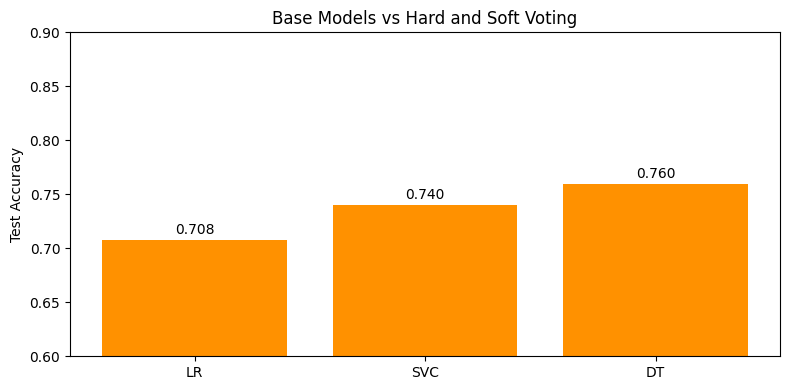

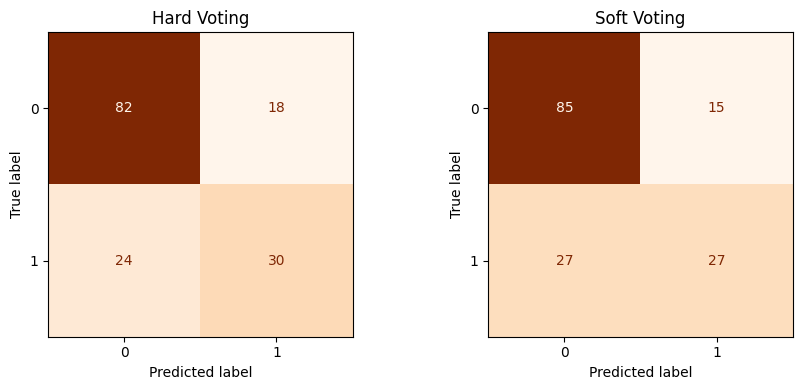

In [66]:
import matplotlib.pyplot as plt

# Base model vs Hard/Soft
plt.figure(figsize=(8, 4))
bars = plt.bar(results.keys(), results.values(),
               color=["#ff9100"] * 3 + ["#6c6a68", "#000000"])
plt.ylim(0.6, 0.9)
plt.ylabel("Test Accuracy")
plt.title("Base Models vs Hard and Soft Voting")
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.005,
             f"{b.get_height():.3f}", ha="center")
plt.tight_layout()
plt.show()

# Confusion Matrices for Hard/Soft
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
ConfusionMatrixDisplay.from_predictions(y_test, hard_pred, ax=axes[0],
                                        cmap="Oranges", colorbar=False)
axes[0].set_title("Hard Voting")
ConfusionMatrixDisplay.from_predictions(y_test, soft_pred, ax=axes[1],
                                        cmap="Oranges", colorbar=False)
axes[1].set_title("Soft Voting")
plt.tight_layout()
plt.show()

Task 6: Train a Bagging Classifier using decision tree base estimators with bootstrap sampling enabled and out-of-bag evaluation, and compare the OOB score against held-out test accuracy. Plot the accuracy results in one graph

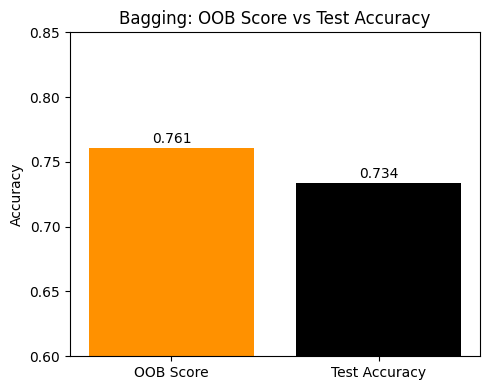

In [67]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

# Bagging Classifier
bag_clf = Pipeline([
    ("prep", preprocessing),
    ("bag", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=500,
        bootstrap=True,      
        oob_score=True,      
        n_jobs=-1,
        random_state=42,
    )),
])

# Train model
bag_clf.fit(X_train, y_train)


# OOB Score 
oob_score = bag_clf.named_steps["bag"].oob_score_
test_acc = accuracy_score(y_test, bag_clf.predict(X_test))

# Plot 
plt.figure(figsize=(5, 4))
bars = plt.bar(["OOB Score", "Test Accuracy"], [oob_score, test_acc],
               color=["#ff9100", "#000000"])
plt.ylim(0.6, 0.85)
plt.ylabel("Accuracy")
plt.title("Bagging: OOB Score vs Test Accuracy")
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.004,
             f"{b.get_height():.3f}", ha="center")
plt.tight_layout()
plt.show()

Task 7: Train a Random Forest Classifier configured with feature subsetting, evaluate its test performance, and generate a horizontal bar plot visualizing feature importances (Mean Decrease in Impurity).

In [68]:
from sklearn.ensemble import RandomForestClassifier

random_forest_clf = Pipeline([
    ("prep", preprocessing),
    ("rf", RandomForestClassifier(
        n_estimators=100,
        max_features="sqrt",
        bootstrap=True,
        n_jobs=-1,
        random_state=42,
    )),
])

# Train model
random_forest_clf.fit(X_train, y_train)

# Test performance
rf_pred = random_forest_clf.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred)
print(f"Random Forest test accuracy: {rf_acc:.4f}\n")
print(classification_report(y_test, rf_pred, target_names=["No Diabetes", "Diabetes"]))


Random Forest test accuracy: 0.7792

              precision    recall  f1-score   support

 No Diabetes       0.81      0.87      0.84       100
    Diabetes       0.72      0.61      0.66        54

    accuracy                           0.78       154
   macro avg       0.76      0.74      0.75       154
weighted avg       0.77      0.78      0.77       154



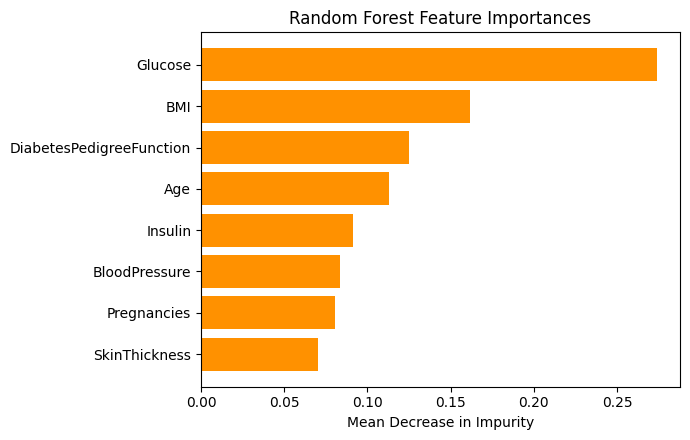

In [69]:
# Feature Importances
rf_model = random_forest_clf.named_steps["rf"]
feature_names = [n.replace("num__", "") for n in random_forest_clf.named_steps["prep"].get_feature_names_out()]
importances = rf_model.feature_importances_

# Plot
sort_by = np.argsort(importances)
plt.figure(figsize=(7, 4.5))
plt.barh(np.array(feature_names)[sort_by], importances[sort_by], color="#ff9100")
plt.xlabel("Mean Decrease in Impurity")
plt.title("Random Forest Feature Importances")
plt.tight_layout()
plt.show()

Task 8: Train an AdaBoost Classifier utilizing decision stumps and sequential sample weighting, and evaluate its training versus test performance to observe potential boosting generalization trends. Plot the results.

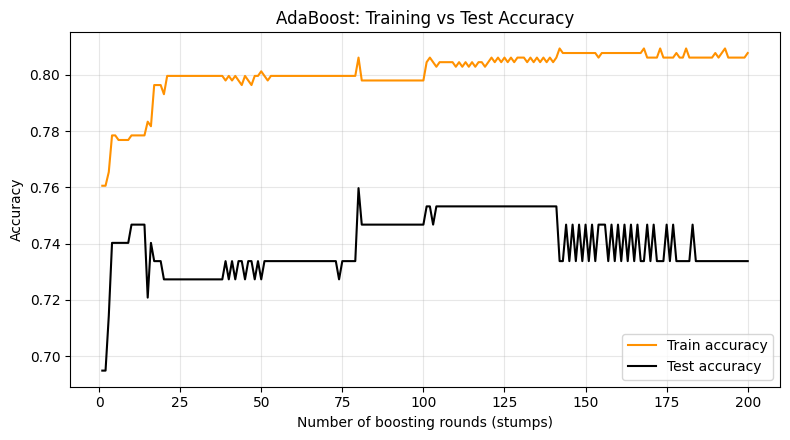

In [70]:
from sklearn.ensemble import AdaBoostClassifier

# AdaBoost Classifier
ada_clf = Pipeline([
    ("prep", preprocessing),
    ("ada", AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
    n_estimators=200,
    learning_rate=0.5,
    random_state=42,
)),
])

# Train model
ada_clf.fit(X_train, y_train)

train_acc = accuracy_score(y_train, ada_clf.predict(X_train))
test_acc = accuracy_score(y_test, ada_clf.predict(X_test))

# Training vs Test
prep = ada_clf.named_steps["prep"]
ada_model = ada_clf.named_steps["ada"]
X_train_prep = prep.transform(X_train)
X_test_prep = prep.transform(X_test)

train_curve = list(ada_model.staged_score(X_train_prep, y_train))
test_curve = list(ada_model.staged_score(X_test_prep, y_test))
rounds = range(1, len(train_curve) + 1)

# Plot
plt.figure(figsize=(8, 4.5))
plt.plot(rounds, train_curve, label="Train accuracy", color="#ff9100")
plt.plot(rounds, test_curve, label="Test accuracy", color="#000000")
plt.xlabel("Number of boosting rounds (stumps)")
plt.ylabel("Accuracy")
plt.title("AdaBoost: Training vs Test Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
